In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

In [13]:
dataset = pd.read_excel("dataset.xlsx")

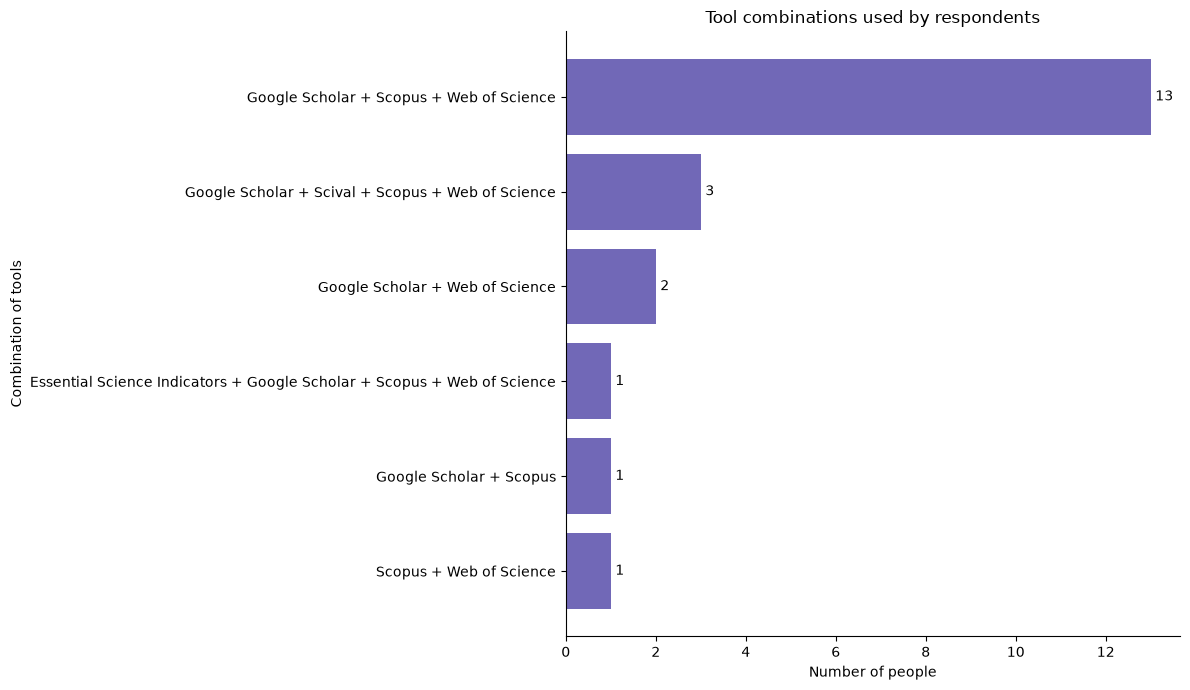

In [15]:
df = dataset.dropna().drop_duplicates()

# OPTIONAL: choose one use case
# Uncomment and change the value below if you want one use case only
# df = df[df['Use'] == 'Individual-Led Research']

# Each person can use multiple tools
person_tools = (
    df.groupby('Name')['Tool']
      .apply(lambda x: frozenset(x.unique()))
)

# Count exact combinations of tools
combo_counts = person_tools.value_counts()

# Convert combinations into readable labels
labels = [
    ' + '.join(sorted(list(combo)))
    for combo in combo_counts.index
]

counts = combo_counts.values

# Limit display if there are lots of combinations
max_combinations = 15
labels = labels[:max_combinations]
counts = counts[:max_combinations]

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(range(len(labels)), counts, color='#7168B7')

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlabel('Number of people')
ax.set_ylabel('Combination of tools')
ax.set_title('Tool combinations used by respondents')

# Add counts to bars
for i, value in enumerate(counts):
    ax.text(value + 0.1, i, str(value), va='center')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()